# **Intelligent Movie Recommendation System Using Multi-Layer Perceptron (MLP)**


This project builds a movie recommendation system using a neural network-based Multi-Layer Perceptron (MLP). It utilizes user ratings, movie genres, and popularity metrics to recommend the most relevant movies for each user.

In [1]:
# Import Libraries
from google.colab import drive

# Mount Google Drive and set directory
drive.mount('/gdrive')
%cd '/gdrive/MyDrive/AI Project'

Mounted at /gdrive
/gdrive/MyDrive/AI Project


### Import Necessary Libraries

This section imports all the required libraries for data loading, preprocessing, building the machine learning model, and evaluating its performance.

In [2]:
# Import Libraries
import pandas as pd # For data manipulation and analysis
import numpy as np # For numerical computations and array handling
import seaborn as sns # For visualisations
import matplotlib.pyplot as plt # to display plots and graphs
import ast  # To safely evaluate string literals
from sklearn.model_selection import train_test_split # to split the dataset into training and testing parts
from sklearn.preprocessing import MinMaxScaler, MultiLabelBinarizer, LabelEncoder # to scale numerical values
from sklearn.metrics import mean_absolute_error, mean_squared_error, confusion_matrix  # to assess the model's performance

# Import TensorFlow libraries to create and train Neural Network models
from tensorflow.keras.models import Sequential, Model  # to build the model
from tensorflow.keras.layers import Dense, Embedding, Flatten, Concatenate, Input # for defining the neural network architecture
from tensorflow.keras.optimizers import Adam # for adaptive and efficient model optimization during training
from tensorflow.keras.callbacks import EarlyStopping # # to stop training early if no improvement
from tensorflow.keras import regularizers  # to prevent overfitting


### Load Datasets

This section loads the ratings dataset and movies metadata dataset. Specific columns from the metadata file are selected to optimize memory usage.

In [3]:
# Load Datasets
# Load the ratings and movies metadata datasets
ratings_file = '/gdrive/MyDrive/AI Project/ratings_small.csv' # Ratings dataset
movies_file = '/gdrive/MyDrive/AI Project/movies_metadata.csv' # Movies metadata dataset

# Load ratings data
ratings = pd.read_csv(ratings_file)
print("Ratings Data Sample:")
print(ratings.head())

# Load movies metadata
titles_to_load = ['id', 'title', 'genres', 'vote_average', 'vote_count', 'budget', 'revenue', 'runtime']
movies = pd.read_csv(movies_file, usecols=titles_to_load, low_memory=False)
print("Movies Metadata Sample:")
print(movies.head())

Ratings Data Sample:
   userId  movieId  rating   timestamp
0       1       31     2.5  1260759144
1       1     1029     3.0  1260759179
2       1     1061     3.0  1260759182
3       1     1129     2.0  1260759185
4       1     1172     4.0  1260759205
Movies Metadata Sample:
     budget                                             genres     id  \
0  30000000  [{'id': 16, 'name': 'Animation'}, {'id': 35, '...    862   
1  65000000  [{'id': 12, 'name': 'Adventure'}, {'id': 14, '...   8844   
2         0  [{'id': 10749, 'name': 'Romance'}, {'id': 35, ...  15602   
3  16000000  [{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...  31357   
4         0                     [{'id': 35, 'name': 'Comedy'}]  11862   

       revenue  runtime                        title  vote_average  vote_count  
0  373554033.0     81.0                    Toy Story           7.7      5415.0  
1  262797249.0    104.0                      Jumanji           6.9      2413.0  
2          0.0    101.0             Gru

The ratings dataset contains four key columns:

*   `userId`: Unique identifier for each user.
*   `movieId`: Unique identifier for each movie.
*   `rating`: User-provided rating for the movie, ranging between 0.5 to 5.0.
*   `timestamp`: A time-based value indicating when the rating was given.

The movies metadata dataset contains the following columns:


*   `id`: Unique identifier for each movie; used for merging datasets.
*   `title`: The movie's name; essential for readable recommendations.
*   `genres`: List of movie genres (e.g., Comedy, Drama).
*   `vote_average`: Average rating of the movie (0–10); indicates audience reception.
*   `vote_count`: Total number of votes received; reflects audience exposure.
*   `budget`: Production cost of the movie; indicates the scale of production.
*   `revenue`: Total earnings of the movie; measures financial success.
*  `runtime`: Duration of the movie in minutes; indicates movie length.












### Data Preprocessing

This section involves cleaning and preparing the data.

#### Clean the Movie Dataset

 It focuses on cleaning the movies dataset by addressing missing or invalid values, extracting relevant genre information and converting data into appropriate formats.

In [4]:
# Parse genres column to extract genre names
def parse_genres(genres_str):
    try:
        genres_list = ast.literal_eval(genres_str)  # Convert string to list
        return [genre['name'] for genre in genres_list]  # Extract 'name' field
    except (ValueError, SyntaxError):
        return []  # Return empty list if parsing fails

# Apply parsing to the 'genres' column
movies['genres'] = movies['genres'].apply(parse_genres)

# Data Cleaning
# Convert columns to appropriate numeric types
movies['id'] = pd.to_numeric(movies['id'], errors='coerce')
movies['budget'] = pd.to_numeric(movies['budget'], errors='coerce')
movies['revenue'] = pd.to_numeric(movies['revenue'], errors='coerce')

# Drop rows with missing or zero values in critical numerical columns
columns_to_check = ['vote_average', 'vote_count', 'budget', 'revenue', 'runtime']
movies.dropna(subset=['id'] + columns_to_check, inplace=True)
movies = movies[(movies[columns_to_check] != 0).all(axis=1)]

# Verify the cleaned dataset
print("Cleaned Movies Data Info:")
print(movies.info())

Cleaned Movies Data Info:
<class 'pandas.core.frame.DataFrame'>
Index: 5362 entries, 0 to 45422
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   budget        5362 non-null   float64
 1   genres        5362 non-null   object 
 2   id            5362 non-null   float64
 3   revenue       5362 non-null   float64
 4   runtime       5362 non-null   float64
 5   title         5362 non-null   object 
 6   vote_average  5362 non-null   float64
 7   vote_count    5362 non-null   float64
dtypes: float64(6), object(2)
memory usage: 377.0+ KB
None


After cleaning, the dataset contains 5,362 movies with no missing or invalid values in critical columns like `budget`, `revenue`, `vote_average`, and `vote_count`.

*  There are 6 numerical columns (e.g., `budget`, `runtime`) and 2 object columns (`genres`, `title`).
*  The dataset is now optimized and ready for merging with the ratings dataset.





####Merge Ratings with Movies Metadata

The ratings and movies datasets are merged to create a single unified dataset for training.



In [5]:
# Merge Ratings and Movies
# Ensure consistent data types for merging
ratings['movieId'] = ratings['movieId'].astype(float)

merged_data = pd.merge(ratings, movies, left_on='movieId', right_on='id', how='inner')  # Merge ratings and movie data using movie IDs

# Display the merged dataset
print("Merged Data Sample:")
print(merged_data.head())

Merged Data Sample:
   userId  movieId  rating   timestamp      budget  \
0       1   1371.0     2.5  1260759135  17000000.0   
1       1   2105.0     4.0  1260759139  11000000.0   
2       1   2294.0     2.0  1260759108  22000000.0   
3       2     62.0     3.0   835355749  10500000.0   
4       2    144.0     3.0   835356016   2500000.0   

                                  genres      id      revenue  runtime  \
0                                [Drama]  1371.0  270000000.0     99.0   
1                      [Comedy, Romance]  2105.0  235483004.0     95.0   
2                               [Comedy]  2294.0   33788161.0    104.0   
3  [Science Fiction, Mystery, Adventure]    62.0   68700000.0    149.0   
4              [Drama, Fantasy, Romance]   144.0    3200000.0    128.0   

                            title  vote_average  vote_count  
0                       Rocky III           6.6       894.0  
1                    American Pie           6.4      2358.0  
2  Jay and Silent Bob St

The merged dataset combines user ratings and movie metadata using the movie ID.

Key observations:


*  `userId` and `rating` represent user behavior.
*   Movie-specific details like `title`, `vote_average`, and `vote_count` are now available for each user-movie interaction.






### Exploratory Data Analysis (EDA)

This section explores the data to understand its distribution, user behavior, and movie popularity.

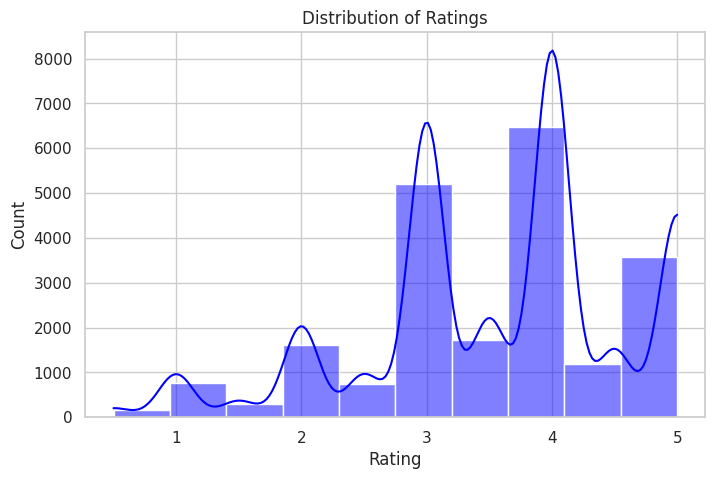

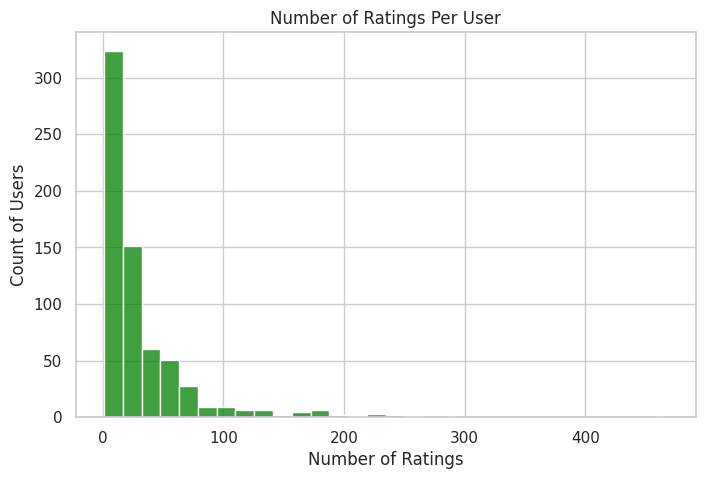

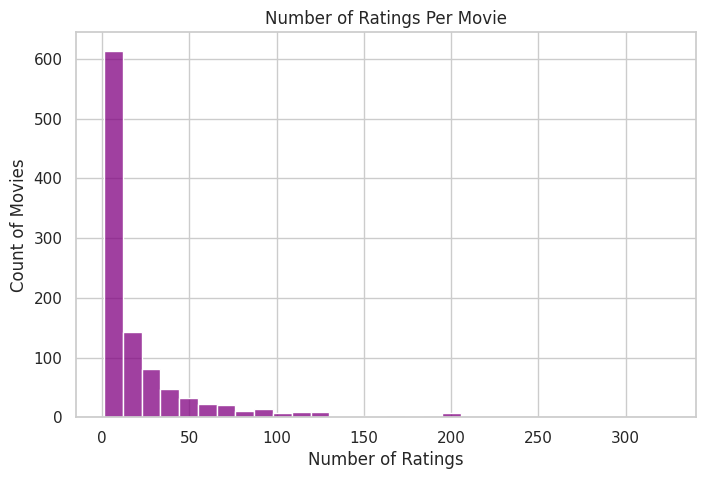

In [6]:
# Exploratory Data Analysis (EDA)
# Rating Distribution
sns.set(style="whitegrid")
plt.figure(figsize=(8, 5))
sns.histplot(merged_data['rating'], bins=10, kde=True, color='blue')
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

# User Activity: Number of Ratings Per User
user_activity = merged_data.groupby('userId')['rating'].count()
plt.figure(figsize=(8, 5))
sns.histplot(user_activity, bins=30, kde=False, color='green')
plt.title("Number of Ratings Per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Count of Users")
plt.show()

# Movie Popularity: Number of Ratings Per Movie
movie_popularity = merged_data.groupby('movieId')['rating'].count()
plt.figure(figsize=(8, 5))
sns.histplot(movie_popularity, bins=30, kde=False, color='purple')
plt.title("Number of Ratings Per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Count of Movies")
plt.show()

**Distribution of Ratings**

This graph displays the distribution of ratings given by users. Here are some key observations:
*   Most ratings are between 3.0 and 4.5, indicating a tendency for users to give positive ratings.
*  Fewer ratings are observed below 2.0, suggesting that users rarely give low rating.


**Number of Ratings Per User**

This graph shows the number of ratings provided by each user. Here are some key observations:

*   The majority of users have rated fewer than 50 movies.
*   Only a few users rate more than 200 movies, showing that most users interact with only a small number of movies.

This highlights a potential data sparsity issue, where many users rate only a few movies.

**Number of Ratings Per Movie**

This graph illustrates the number of ratings received by each movie. Here are some key observations:



*  Most movies get fewer than 50 ratings, while a small group of popular movies gets over 200 ratings.
*  Popular movies dominate engagement, while many movies receive very few ratings.


This shows the data is unevenly distributed, which must be considered when building the recommendation model.

### Feature Encoding and Scaling

Here, categorical features and scale numerical features are encoded for efficient model training.

In [7]:
# Feature Encoding
# Encode userId and movieId
label_encoder_user = LabelEncoder()
label_encoder_movie = LabelEncoder()
merged_data['userId'] = label_encoder_user.fit_transform(merged_data['userId'])
merged_data['movieId'] = label_encoder_movie.fit_transform(merged_data['movieId'])

# Genre Encoding: Multi-hot encoding
mlb = MultiLabelBinarizer()
merged_data['genres'] = merged_data['genres'].apply(lambda x: x if isinstance(x, list) else [])
genres_encoded = mlb.fit_transform(merged_data['genres'])
genres_df = pd.DataFrame(genres_encoded, columns=mlb.classes_)

# Concatenate encoded genres with the dataset
merged_data = pd.concat([merged_data, genres_df], axis=1)

# Scale Numerical Features
scaler = MinMaxScaler()
scaled_columns = ['vote_average', 'vote_count', 'runtime', 'budget', 'revenue']
merged_data[scaled_columns] = scaler.fit_transform(merged_data[scaled_columns])

# Verify encoded and scaled data
print("Encoded and Scaled Data Sample:")
print(merged_data.head())


Encoded and Scaled Data Sample:
   userId  movieId  rating   timestamp    budget  \
0       0      467     2.5  1260759135  0.044737   
1       0      657     4.0  1260759139  0.028947   
2       0      697     2.0  1260759108  0.057895   
3       1       19     3.0   835355749  0.027632   
4       1       64     3.0   835356016  0.006579   

                                  genres      id   revenue   runtime  \
0                                [Drama]  1371.0  0.146339  0.220000   
1                      [Comedy, Romance]  2105.0  0.127631  0.193333   
2                               [Comedy]  2294.0  0.018313  0.253333   
3  [Science Fiction, Mystery, Adventure]    62.0  0.037235  0.553333   
4              [Drama, Fantasy, Romance]   144.0  0.001734  0.413333   

                            title  ...  Fantasy  History  Horror  Music  \
0                       Rocky III  ...        0        0       0      0   
1                    American Pie  ...        0        0       0      0 

The dataset is encoded and scaled, with user and movie IDs as numerical values, genres as multi-hot encoded columns, and numerical features like `budget` and `revenue` normalized. It is now ready for model training.

### Train-Test Split

Here, the dataset is split into training, validation, and test sets for model training and evaluation.

In [8]:
# Train-Test Split
# Separate features and target variable
y = merged_data['rating']
user_input = merged_data[['userId']]
movie_input = merged_data[['movieId']]
numerical_features = merged_data[['vote_average', 'vote_count', 'runtime', 'budget', 'revenue']]

# Train-validation-test split (Split data into training, validation, and test sets)
X_train_user, X_temp_user, X_train_movie, X_temp_movie, X_train_num, X_temp_num, y_train, y_temp = train_test_split(
    user_input, movie_input, numerical_features, y, test_size=0.2, random_state=42
)
X_val_user, X_test_user, X_val_movie, X_test_movie, X_val_num, X_test_num, y_val, y_test = train_test_split(
    X_temp_user, X_temp_movie, X_temp_num, y_temp, test_size=0.5, random_state=42
)

print(f"Training data size: {len(X_train_user)}")
print(f"Validation data size: {len(X_val_user)}")
print(f"Test data size: {len(X_test_user)}")


Training data size: 17380
Validation data size: 2173
Test data size: 2173


The dataset has been divided into three subsets:


*   **Training Set:** 17,380 records, used to train the neural network.
*   **Validation Set:** 2,173 records, used to monitor the model's performance during training.
*   **Test Set:** 2,173 records, used for final evaluation after training.

This split ensures that the model generalizes well and does not overfit the training data.

### Model Training

This section defines an MLP architecture with embedding layers and train the model using MSE loss.

In [9]:
# Build and Train MLP Model
# Define Input Layers
user_input_layer = Input(shape=(1,), name="User_Input")
movie_input_layer = Input(shape=(1,), name="Movie_Input")
num_input_layer = Input(shape=(5,), name="Numerical_Input")

# Embedding Layers for UserId and MovieId
user_embedding = Embedding(input_dim=user_input['userId'].max() + 1, output_dim=50)(user_input_layer)
movie_embedding = Embedding(input_dim=movie_input['movieId'].max() + 1, output_dim=50)(movie_input_layer)

# Flatten Embedding Outputs
user_flatten = Flatten()(user_embedding)
movie_flatten = Flatten()(movie_embedding)

# Concatenate All Inputs
concat_layer = Concatenate()([user_flatten, movie_flatten, num_input_layer])

# Add Hidden Layers
hidden_1 = Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01))(concat_layer)
hidden_2 = Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.01))(hidden_1)
hidden_3 = Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.01))(hidden_2)

# Output Layer
output = Dense(1, activation='linear')(hidden_3)

# Compile the Model
model = Model(inputs=[user_input_layer, movie_input_layer, num_input_layer], outputs=output)
model.compile(optimizer=Adam(), loss='mean_squared_error', metrics=['mean_absolute_error'])

# Early Stopping Callback
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train the Model
history = model.fit(
    [X_train_user, X_train_movie, X_train_num], y_train,
    validation_data=([X_val_user, X_val_movie, X_val_num], y_val),
    epochs=20, batch_size=64, callbacks=[early_stopping]
)


Epoch 1/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 2.9030 - mean_absolute_error: 1.0138 - val_loss: 1.1942 - val_mean_absolute_error: 0.7006
Epoch 2/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.0290 - mean_absolute_error: 0.6727 - val_loss: 1.0016 - val_mean_absolute_error: 0.6895
Epoch 3/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.8997 - mean_absolute_error: 0.6597 - val_loss: 0.9447 - val_mean_absolute_error: 0.6901
Epoch 4/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.8435 - mean_absolute_error: 0.6542 - val_loss: 0.9178 - val_mean_absolute_error: 0.6933
Epoch 5/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.8111 - mean_absolute_error: 0.6501 - val_loss: 0.8984 - val_mean_absolute_error: 0.6907
Epoch 6/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7933 - mean_absolute_error: 0.6489 - val_loss: 0.8845 - val_mean_absolute_error: 0.7069
Epoch 7/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7755 - mean_absolute_error: 0.6462 - v






*   **Loss and Mean Absolute Error (MAE):** The training loss and MAE consistently decrease across epochs, indicating the model is effectively learning patterns from the data.
*  **Validation Loss:** Validation loss stabilizes around 0.83, with MAE near 0.70, suggesting the model generalizes well to unseen data without overfitting.
*   **Final MAE:** An MAE of approximately 0.63 on the training set and 0.70 on the validation set indicates the model's predictions are reasonably close to actual ratings.



### Results and Evaluation

The model's performance is evaluated using key metrics like Mean Absolute Error (MAE) and visualizations.

In [10]:
# Model Evaluation
# Evaluate on Test Data
y_pred = model.predict([X_test_user, X_test_movie, X_test_num])

# Convert predictions to integers for classification metrics
y_pred_rounded = np.round(y_pred).astype(int)
y_test_rounded = np.round(y_test).astype(int)

# Calculate Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)


print(f"Test MAE: {mae}")
print(f"Test MSE: {mse}")



68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Test MAE: 0.7316638683318214
Test MSE: 0.8811144177178887




**Test MAE (Mean Absolute Error):** 0.73 indicates that, on average, the model's predicted ratings deviate by approximately 0.73 from the actual ratings.

**Test MSE (Mean Squared Error):** 0.88 shows the variance of errors, with a slightly higher penalty for larger deviations.











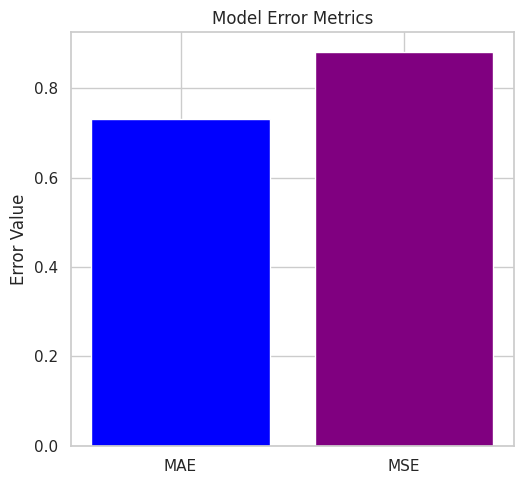

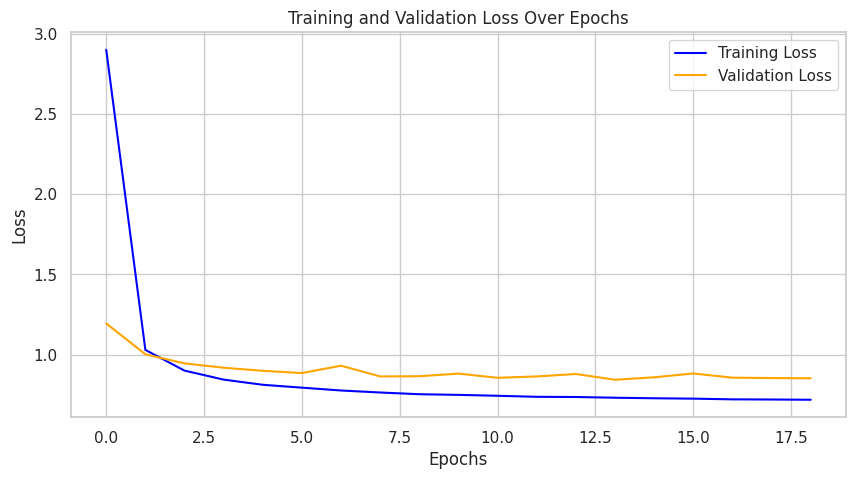

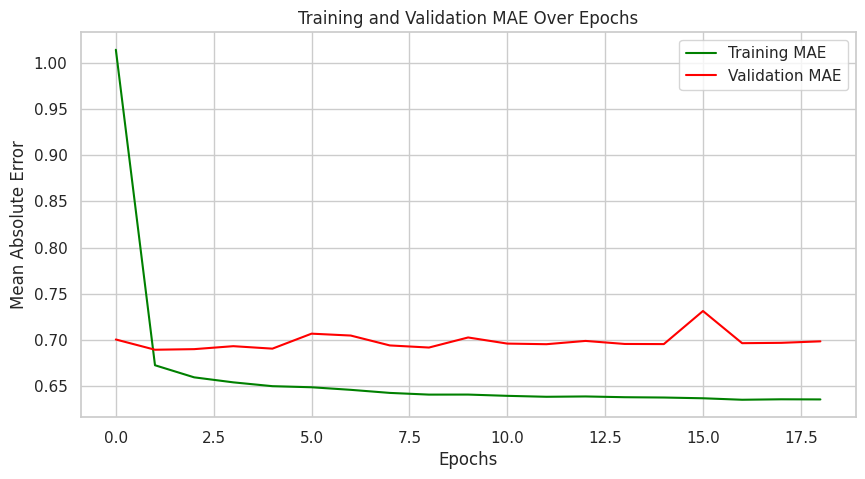

In [11]:
# Plot evaluation metrics
plt.figure(figsize=(10, 5))

# Plot Mean Absolute Error
plt.subplot(1, 2, 1)
plt.bar(['MAE', 'MSE'], [mae, mse], color=['blue', 'purple'])
plt.title("Model Error Metrics")
plt.ylabel("Error Value")

plt.tight_layout()
plt.show()

# Plot Loss and MAE Trends
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Over Epochs")
plt.legend()
plt.show()

# MAE Trend
plt.figure(figsize=(10, 5))
plt.plot(history.history['mean_absolute_error'], label='Training MAE', color='green')
plt.plot(history.history['val_mean_absolute_error'], label='Validation MAE', color='red')
plt.xlabel("Epochs")
plt.ylabel("Mean Absolute Error")
plt.title("Training and Validation MAE Over Epochs")
plt.legend()
plt.show()


**Error Metrics:**

MAE and MSE indicate a reasonable error margin, with MAE slightly lower, emphasizing the average error.

**Loss and MAE Trends:**


*   The training loss and Mean Absolute Error (MAE) consistently decreased across epochs, validating the model's ability to learn patterns effectively.
*  The validation loss and MAE stabilized around 0.84 and 0.70 respectively, indicating the model generalizes well without overfitting.




### Personalized Movie Recommendation

This section generates movie recommendations based on user preferences or provides top-rated movies for new users. The recommendations:



*  **For Existing Users:** Are based on their ratings and genre preferences, ensuring variety and uniqueness.
*   **For New Users:** Suggestions are chosen from the highest-rated movies, offering meaningful options even without prior user data.








In [12]:
# Recommendation Function
def recommend_movies(user_id, num_recommendations=5):
    """
    Recommend unique and personalized movies for a given user or top-rated movies for new users.
    """
    if user_id in label_encoder_user.classes_:
        # Encode the user ID
        user_idx = label_encoder_user.transform([user_id])[0]

        # Predict ratings for all movies for the specific user
        user_input_test = np.full((movie_input.shape[0], 1), user_idx)
        movie_scores = model.predict([user_input_test, movie_input, numerical_features], verbose=0)
        merged_data['predicted_rating'] = movie_scores.flatten()

        # Filter out movies already rated by the user
        rated_movies = merged_data[merged_data['userId'] == user_idx]['movieId'].values
        unrated_movies = merged_data[~merged_data['movieId'].isin(rated_movies)].copy()

        # Process genres consistently
        unrated_movies['genres'] = unrated_movies['genres'].apply(
            lambda x: x if isinstance(x, list) else (eval(x) if isinstance(x, str) else [])
        )

        # Get the user's past ratings and their preferred genres
        user_rated_movies = merged_data[merged_data['userId'] == user_idx]
        user_genre_preferences = (
            user_rated_movies.explode('genres')
            .groupby('genres')['rating']
            .mean()
            .sort_values(ascending=False)
            .index.tolist()
        )

        # Diversify recommendations by iterating over preferred genres
        recommendations = []
        added_movie_ids = set()
        for genre in user_genre_preferences:
            genre_movies = unrated_movies[unrated_movies['genres'].apply(lambda g: genre in g)]
            genre_movies = genre_movies[~genre_movies['movieId'].isin(added_movie_ids)]
            if not genre_movies.empty:
                top_genre_movies = genre_movies.sort_values('predicted_rating', ascending=False).head(1)
                recommendations.append(top_genre_movies)
                added_movie_ids.update(top_genre_movies['movieId'])

            # Break if enough recommendations are collected
            if len(recommendations) >= num_recommendations:
                break

        # If not enough recommendations, fill with highest-rated movies
        if len(recommendations) < num_recommendations:
            remaining_movies = unrated_movies[~unrated_movies['movieId'].isin(added_movie_ids)]
            top_remaining = remaining_movies.sort_values('predicted_rating', ascending=False).head(
                num_recommendations - len(recommendations)
            )
            recommendations.append(top_remaining)

        # Combine recommendations and ensure uniqueness
        recommendations_df = pd.concat(recommendations).drop_duplicates('movieId').head(num_recommendations)

        print(f"Top {num_recommendations} Recommendations for User {user_id}:")
        return recommendations_df[['title', 'genres']].reset_index(drop=True)

    else:
        # New user handling: recommend top-rated movies based on votes
        print("New user detected. Providing top-rated movies.")
        movies['genres'] = movies['genres'].apply(
            lambda x: x if isinstance(x, list) else (eval(x) if isinstance(x, str) else [])
        )
        top_movies = (
            movies.sort_values(['vote_average', 'vote_count'], ascending=False)
            .drop_duplicates('id')
            .head(num_recommendations)
        )
        return top_movies[['title', 'genres']].reset_index(drop=True)

# Interactive Usage
try:
    user_input_id = int(input("Enter User ID for recommendations: "))
    recommendations = recommend_movies(user_id=user_input_id)
    print(recommendations)
except ValueError:
    print("Invalid input. Please enter a numeric User ID.")


Enter User ID for recommendations: 1
Top 5 Recommendations for User 1:
                   title                    genres
0              Ninotchka         [Comedy, Romance]
1     You, Me and Dupree         [Comedy, Romance]
2              Elizabeth          [Drama, History]
3  Sense and Sensibility          [Drama, Romance]
4   Strangers on a Train  [Crime, Drama, Thriller]
